<div style="background:linear-gradient(120deg,#0B2B1F 0%,#1B4332 55%,#2D6A4F 100%);padding:30px 34px;border-radius:18px;color:#F7F3E8">
<div style="font-size:13px;letter-spacing:4px;color:#F2B705">UNIT 3 · FINAL PROJECT · TUWAIQ ACADEMY</div>
<div style="font-size:38px;font-weight:800;margin:6px 0 4px 0">🦜 Feathers &amp; Borders</div>
<div style="font-size:18px;opacity:.92">Fifty years of the global live-parrot trade, and why some species end up in cages while others don't</div>
<div style="font-size:16px;margin-top:10px;color:#F2B705">ريش بلا حدود: رحلة الببغاوات من الغابة إلى القفص</div>
<div style="margin-top:16px;font-size:14px;opacity:.85">Norah Alsuwailem · Data Science &amp; AI Bootcamp</div>
</div>

## 1 · Dataset & Problem Definition

| | Dataset | Source | One row = |
|---|---|---|---|
| 🧾 | **CITES Trade Database**: live parrots (Psittaciformes), 1975–2024, comparative tabulation | [trade.cites.org](https://trade.cites.org) · UNEP-WCMC | one reported trade record |
| 🪶 | **AVONET**: morphological, ecological & geographical data for all birds | Tobias *et al.* (2022), *Ecology Letters* | one bird species |

**Why this dataset?** I own a green-cheeked conure 💚, and caring for him made me curious about where pet parrots come from. Parrots are the most traded group of birds in the world and one of the most threatened.

**Main question:** *Which parrots end up in the global trade, and how has that trade changed in 50 years?*

1. How big is the trade, and has it shifted from **wild-caught** to **captive-bred** birds?
2. Who exports and who imports? Where do **Saudi Arabia and the Gulf** fit?
3. Is the trade concentrated in a few species?
4. Do **size, diet, habitat or range** predict how much a species is traded?
5. Which species have a **tiny natural range** but **heavy wild-caught trade**?

## 2 · Data Loading & Structure
### 2.1 CITES trade records

In [1]:
import pandas as pd

In [2]:
trade_raw = pd.read_csv("../data/raw/cites_parrots.csv", low_memory=False)
trade_raw.head()

,Year,App.,Taxon,Class,Order,Family,Genus,Importer,Exporter,Origin,Importer reported quantity,Exporter reported quantity,Term,Unit,Purpose,Source
0,1975,I,Anodorhynchus leari,Aves,Psittaciformes,Psittacidae,Anodorhynchus,CH,PT,NaN,2.0,NaN,live,NaN,Z,NaN
1,1975,II,Probosciger aterrimus,Aves,Psittaciformes,Cacatuidae,Probosciger,CH,DE,NaN,1.0,NaN,live,NaN,P,C
2,1975,II,Eunymphicus cornutus,Aves,Psittaciformes,Psittacidae,Eunymphicus,CH,NC,NaN,6.0,NaN,live,NaN,P,NaN
3,1975,II,Prosopeia personata,Aves,Psittaciformes,Psittacidae,Prosopeia,CH,BE,NaN,4.0,NaN,live,NaN,P,NaN
4,1975,II,Tanygnathus lucionensis,Aves,Psittaciformes,Psittacidae,Tanygnathus,CH,PH,NaN,9.0,NaN,live,NaN,T,NaN


In [3]:
trade_raw.shape

(219115, 16)

In [4]:
trade_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 219115 entries, 0 to 219114
Data columns (total 16 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Year                        219115 non-null  int64  
 1   App.                        219115 non-null  str    
 2   Taxon                       219115 non-null  str    
 3   Class                       219115 non-null  str    
 4   Order                       219115 non-null  str    
 5   Family                      218793 non-null  str    
 6   Genus                       218516 non-null  str    
 7   Importer                    216828 non-null  str    
 8   Exporter                    218123 non-null  str    
 9   Origin                      57239 non-null   str    
 10  Importer reported quantity  102356 non-null  float64
 11  Exporter reported quantity  157796 non-null  float64
 12  Term                        219115 non-null  str    
 13  Unit                     

In [5]:
trade_raw.describe()
#the mean 117 is bigger than the median 6 so most shipments are small but a few are very big

,Year,Importer reported quantity,Exporter reported quantity
count,219115.000000,102356.000000,157796.000000
mean,2003.627716,117.794200,117.309735
std,11.839509,1030.176769,893.146926
min,1975.000000,0.200000,1.000000
25%,1994.000000,2.000000,2.000000
50%,2002.000000,6.000000,8.000000
75%,2014.000000,30.000000,33.000000
max,2024.000000,124000.000000,90700.000000


In [6]:
trade_raw.loc[trade_raw["Importer reported quantity"].idxmax()]
#find the biggest shipment in the data it was 124000 wild monk parakeets from uruguay to mexico in 2012

Year                                         2012
App.                                           II
Taxon                         Myiopsitta monachus
Class                                        Aves
Order                              Psittaciformes
Family                                Psittacidae
Genus                                  Myiopsitta
Importer                                       MX
Exporter                                       UY
Origin                                        NaN
Importer reported quantity               124000.0
Exporter reported quantity                77700.0
Term                                         live
Unit                                          NaN
Purpose                                         T
Source                                          W
Name: 152931, dtype: object

In [7]:
trade_raw.isnull().sum()

Year                               0
App.                               0
Taxon                              0
Class                              0
Order                              0
Family                           322
Genus                            599
Importer                        2287
Exporter                         992
Origin                        161876
Importer reported quantity    116759
Exporter reported quantity     61319
Term                               0
Unit                          202980
Purpose                        21838
Source                         34457
dtype: int64

### ملاحظات على بيانات CITES
- 219,115 صف و16 عمود، وكل صف هو تقرير شحنة وليس طائراً واحداً
- Unit الفارغ = عدد طيور (القيمة الافتراضية)
- Origin المعبأ = إعادة تصدير، يجب حذفه لتجنب العد المزدوج
- عمودان للكمية، وعمود المستورد ناقص أكثر من عمود المصدّر

### 2.2 AVONET bird traits
The Excel file has several sheets. We use **AVONET1_BirdLife**, whose taxonomy is closest to CITES, save it as CSV, and keep the **404 parrot species**.

In [8]:
avonet_all = pd.read_excel("../data/raw/AVONET Supplementary dataset 1.xlsx",
                           sheet_name="AVONET1_BirdLife")
avonet_all.to_csv("../data/raw/AVONET1_BirdLife.csv", index=False)
avonet_all.shape
#i used the BirdLife sheet because its bird names are the closest to CITES

(11009, 37)

In [9]:
#keep parrots only (order = Psittaciformes)
parrots_raw = avonet_all[avonet_all["Order1"] == "Psittaciformes"]
print(parrots_raw.shape)
parrots_raw.head()

(404, 37)


,Sequence,Species1,Family1,Order1,Avibase.ID1,Total.individuals,Female,Male,Unknown,Complete.measures,...,Habitat.Density,Migration,Trophic.Level,Trophic.Niche,Primary.Lifestyle,Min.Latitude,Max.Latitude,Centroid.Latitude,Centroid.Longitude,Range.Size
10176,4100.0,Cacatua alba,Cacatuidae,Psittaciformes,AVIBASE-AF71785D,4,1,1,2,4,...,1,1.0,Herbivore,Omnivore,Insessorial,-0.92,2.23,0.69,127.94,20920.49
10177,4094.0,Cacatua ducorpsii,Cacatuidae,Psittaciformes,AVIBASE-D238FDA1,4,1,3,0,4,...,1,1.0,Herbivore,Omnivore,Insessorial,-9.95,-5.01,-7.84,157.95,32952.62
10178,4096.0,Cacatua galerita,Cacatuidae,Psittaciformes,AVIBASE-3F907C52,5,2,3,0,4,...,1,1.0,Herbivore,Omnivore,Insessorial,-43.64,0.04,-21.00,142.30,3905044.34
10179,4093.0,Cacatua goffiniana,Cacatuidae,Psittaciformes,AVIBASE-67EE6F84,4,0,2,2,4,...,2,1.0,Herbivore,Granivore,Insessorial,-8.35,-7.10,-7.61,131.37,4111.87
10180,4095.0,Cacatua haematuropygia,Cacatuidae,Psittaciformes,AVIBASE-E1E59398,6,2,4,0,4,...,2,1.0,Herbivore,Granivore,Insessorial,4.61,15.06,10.02,120.81,22755.84


In [10]:
parrots_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 404 entries, 10176 to 10579
Data columns (total 37 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Sequence            404 non-null    float64
 1   Species1            404 non-null    str    
 2   Family1             404 non-null    str    
 3   Order1              404 non-null    str    
 4   Avibase.ID1         404 non-null    str    
 5   Total.individuals   404 non-null    int64  
 6   Female              404 non-null    int64  
 7   Male                404 non-null    int64  
 8   Unknown             404 non-null    int64  
 9   Complete.measures   404 non-null    int64  
 10  Beak.Length_Culmen  404 non-null    float64
 11  Beak.Length_Nares   404 non-null    float64
 12  Beak.Width          404 non-null    float64
 13  Beak.Depth          404 non-null    float64
 14  Tarsus.Length       404 non-null    float64
 15  Wing.Length         404 non-null    float64
 16  Kipps.Distanc

In [11]:
parrots_raw.describe()

,Sequence,Total.individuals,Female,Male,Unknown,Complete.measures,Beak.Length_Culmen,Beak.Length_Nares,Beak.Width,Beak.Depth,...,Hand-Wing.Index,Tail.Length,Mass,Habitat.Density,Migration,Min.Latitude,Max.Latitude,Centroid.Latitude,Centroid.Longitude,Range.Size
count,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,...,404.000000,404.000000,404.000000,404.000000,403.000000,399.000000,399.000000,399.000000,399.000000,3.990000e+02
mean,4283.403465,5.769802,1.972772,2.732673,1.064356,4.240099,26.280198,21.727723,13.119307,22.565842,...,40.162129,118.349505,190.273441,1.423267,1.047146,-12.179151,-1.193333,-6.745280,35.406308,8.238781e+05
std,120.734366,4.357929,2.004152,2.406117,1.655375,1.795853,12.166117,10.914539,5.520067,11.692676,...,6.655800,75.898251,225.954980,0.542536,0.223630,16.511607,15.307173,15.290661,101.001457,1.621508e+06
min,4076.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.600000,6.700000,3.300000,5.900000,...,12.800000,25.500000,8.540000,1.000000,1.000000,-55.720000,-49.630000,-49.690000,-176.300000,2.110000e+00
25%,4177.750000,4.000000,1.000000,2.000000,0.000000,4.000000,18.175000,14.700000,9.275000,14.775000,...,36.050000,71.900000,61.575000,1.000000,1.000000,-23.015000,-9.445000,-16.190000,-64.925000,1.845950e+04
50%,4282.500000,5.000000,2.000000,2.000000,0.000000,4.000000,23.300000,19.100000,11.950000,19.800000,...,40.750000,104.200000,116.455000,1.000000,1.000000,-10.250000,-1.140000,-5.140000,41.300000,1.338930e+05
75%,4388.250000,6.000000,2.000000,3.000000,2.000000,4.000000,31.325000,26.025000,15.600000,27.500000,...,44.625000,140.000000,215.500000,2.000000,1.000000,-1.890000,9.890000,2.485000,135.030000,7.549929e+05
max,4495.000000,66.000000,27.000000,34.000000,10.000000,16.000000,97.700000,83.900000,42.500000,85.100000,...,54.700000,554.500000,1732.050000,3.000000,3.000000,26.740000,35.230000,30.150000,178.800000,8.731069e+06


In [12]:
parrots_raw.isnull().sum()

Sequence                0
Species1                0
Family1                 0
Order1                  0
Avibase.ID1             0
Total.individuals       0
Female                  0
Male                    0
Unknown                 0
Complete.measures       0
Beak.Length_Culmen      0
Beak.Length_Nares       0
Beak.Width              0
Beak.Depth              0
Tarsus.Length           0
Wing.Length             0
Kipps.Distance          0
Secondary1              0
Hand-Wing.Index         0
Tail.Length             0
Mass                    0
Mass.Source             0
Mass.Refs.Other       369
Inference               0
Traits.inferred       379
Reference.species     379
Habitat                 2
Habitat.Density         0
Migration               1
Trophic.Level           0
Trophic.Niche           0
Primary.Lifestyle       0
Min.Latitude            5
Max.Latitude            5
Centroid.Latitude       5
Centroid.Longitude      5
Range.Size              5
dtype: int64

In [13]:
#the lightest and the heaviest parrot
print("lightest:", parrots_raw["Mass"].min())
print("heaviest", parrots_raw["Mass"].max())

lightest: 8.54
heaviest 1732.05


In [14]:
#sort by weight then take the first row (lightest) and the last row (heaviest)
#the heaviest is the kakapo from new zealand, the only parrot that cant fly
parrots_raw.sort_values("Mass")[["Species1", "Mass"]].iloc[[0, -1]]

,Species1,Mass
10283,Charmosyna amabilis,8.54
10579,Strigops habroptila,1732.05


In [15]:
#the big ones (Mass.Refs.Other, Traits.inferred...) are just reference notes i dont need them
#Range.Size has only 5 missing so i will keep them as NaN (I dont want to invent numbers)
missing = parrots_raw.isnull().sum()
missing[missing > 0]

Mass.Refs.Other       369
Traits.inferred       379
Reference.species     379
Habitat                 2
Migration               1
Min.Latitude            5
Max.Latitude            5
Centroid.Latitude       5
Centroid.Longitude      5
Range.Size              5
dtype: int64

## 3 · Data Cleaning: CITES

| # | Problem | Fix |
|---|---|---|
| 1 | Duplicate rows | `drop_duplicates()` (3 rows) |
| 2 | Units in kg / g / shipments | keep *number of specimens* only (40 rows) |
| 3 | Re-exports count the same bird twice | drop rows with an `Origin` (57,226 rows) |
| 4 | Two partial quantity columns | exporter's figure, else the importer's |
| 5 | Cryptic codes (`W`, `C`, `T`…) | map to readable labels, missing → "Unknown" |
| 6 | Messy column names | rename to `snake_case` |
| 7 | Subspecies, `spp.` and hybrids | first two words = species; `spp.`/hybrids → NaN |
| 8 | Country codes | readable names with `pycountry` |
| 9 | Wrong dtypes | `int` and `category` |

In [16]:
#make a copy so the original data
trade = trade_raw.copy()
print("قبل التنظيف:", len(trade))

قبل التنظيف: 219115


In [17]:
#remove duplicate rows
print("duplicate:", trade.duplicated().sum())
trade = trade.drop_duplicates()
print("after delete duplicate", len(trade))

duplicate: 3


after delete duplicate 219112


In [18]:
#check the units
#empty unit means "number of birds" (this is the default in CITES)
trade["Unit"].value_counts(dropna=False)

Unit
NaN                    202977
Number of specimens     16095
kg                         30
shipments                   7
g                           3
Name: count, dtype: int64

In [19]:
trade = trade[trade["Unit"].isna() | (trade["Unit"] == "Number of specimens")]
print("بعد فلترة الوحدات:", len(trade))
#keep only rows counted in birds
#i removed kg, g and shipments because i cant add them to bird numbers

بعد فلترة الوحدات: 219072


In [20]:
#re-exports
#if origin has a value, the bird was exported before from another country
#ex: Ghana -> Netherlands -> Germany (same bird, two records)
print("صفوف إعادة التصدير:", trade["Origin"].notna().sum())

صفوف إعادة التصدير: 57226


In [21]:
#remove re-exports to avoid counting the same bird twice
trade = trade[trade["Origin"].isna()]
print("بعد حذف إعادة التصدير:", len(trade))

بعد حذف إعادة التصدير: 161846


In [22]:
#make one quantity column
#use the exporter number first (it has fewer missing values), and if it is empty, use the importer number
trade["quantity"] = trade["Exporter reported quantity"].fillna(trade["Importer reported quantity"])

In [23]:
#check that every row has a quantity now
print("كميات ناقصة:", trade["quantity"].isna().sum())
print("إجمالي الطيور:", f"{trade['quantity'].sum():,.0f}")

كميات ناقصة: 0
إجمالي الطيور: 22,520,296


In [24]:
#look at the source codes (W, C, F...)
trade["Source"].value_counts(dropna=False)

Source
C      101641
NaN     23541
W       20173
F       10783
I        1825
U        1576
R         929
O         724
D         654
Name: count, dtype: int64

In [25]:
#change the source codes to clear names
#i put C, F and D together as "Captive-bred" because they all mean born in captivity
source_map = {
    "W": "Wild-caught",    # مصطاد من البرية
    "C": "Captive-bred",   # مُربّى في الأسر
    "F": "Captive-bred",   # مولود في الأسر
    "D": "Captive-bred",   # مُربّى تجارياً (أنواع مهددة)
    "R": "Ranched",        # مُربّى في مزرعة من بيض بري
    "I": "Confiscated",    # مصادَر
    "O": "Pre-Convention", # قبل الاتفاقية
    "U": "Unknown",        # غير معروف
}
#empty source -> "Unknown" (I didn't delete them because they are real birds)
trade["source"] = trade["Source"].map(source_map).fillna("Unknown")
trade["source"].value_counts()

source
Captive-bred      113078
Unknown            25117
Wild-caught        20173
Confiscated         1825
Ranched              929
Pre-Convention       724
Name: count, dtype: int64

In [26]:
#same idea for the purpose codes (T = Commercial, P = Personal...)
purpose_map = {
    "T": "Commercial", "P": "Personal", "B": "Breeding", "Z": "Zoo",
    "Q": "Circus / show", "S": "Scientific", "N": "Reintroduction",
    "E": "Educational", "L": "Law enforcement", "H": "Hunting trophy",
    "M": "Medical", "G": "Botanical garden",
}
trade["purpose"] = trade["Purpose"].map(purpose_map).fillna("Unknown")
trade["purpose"].value_counts()

purpose
Commercial          103605
Personal             28265
Unknown              16934
Breeding              7845
Zoo                   3090
Circus / show         1539
Scientific             329
Educational            124
Reintroduction          69
Hunting trophy          21
Law enforcement         14
Medical                  9
Botanical garden         2
Name: count, dtype: int64

In [27]:
#rename columns to short snake_case names (easier to write in code)
trade = trade.rename(columns={
    "Year": "year",
    "App.": "cites_appendix",
    "Taxon": "taxon",
    "Family": "family",
    "Genus": "genus",
    "Importer": "importer_code",
    "Exporter": "exporter_code",
})
trade.columns

Index(['year', 'cites_appendix', 'taxon', 'Class', 'Order', 'family', 'genus',
       'importer_code', 'exporter_code', 'Origin',
       'Importer reported quantity', 'Exporter reported quantity', 'Term',
       'Unit', 'Purpose', 'Source', 'quantity', 'source', 'purpose'],
      dtype='str')

In [28]:
#fill missing countries with "XX" (CITES uses XX for unknown country)
trade["importer_code"] = trade["importer_code"].fillna("XX")
trade["exporter_code"] = trade["exporter_code"].fillna("XX")
trade["family"] = trade["family"].fillna("Unknown")

In [29]:
#find names with 3 words or more (these are subspecies)
trade[trade["taxon"].str.count(" ") >= 2]["taxon"].value_counts()

taxon
Psittacus erithacus timneh            1017
Eos squamata riciniata                 117
Alisterus chloropterus mozskowskii       5
Northiella haematogaster narethae        3
Coracopsis nigra barklyi                 2
Amazona festiva festiva                  1
Name: count, dtype: int64

In [30]:
import numpy as np

# أول كلمتين من الاسم = النوع
trade["species"] = trade["taxon"].str.split().str[:2].str.join(" ")

# التيمني صار نوع مستقل
trade.loc[trade["taxon"] == "Psittacus erithacus timneh", "species"] = "Psittacus timneh"

# الجنس الكامل (spp.) والهجين ما لهم نوع
trade.loc[trade["taxon"].str.contains("spp|hybrid", case=False), "species"] = np.nan

print("سجلات لها نوع:", trade["species"].notna().sum())
print("سجلات بدون نوع:", trade["species"].isna().sum())

سجلات لها نوع: 159483
سجلات بدون نوع: 2363


In [31]:
#install pycountry (a library with country names)
%pip install pycountry

Note: you may need to restart the kernel to use updated packages.


In [32]:
import pycountry

#change country codes (like SA) to country names
def country_name(code):
    if code == "XX":
        return "Unknown"
    c = pycountry.countries.get(alpha_2=code)
    if c is None:
        return code  # كود مو موجود في المكتبة، نخليه مثل ما هو
    return getattr(c, "common_name", c.name) #use the short name if it exists

trade["exporter"] = trade["exporter_code"].apply(country_name)
trade["importer"] = trade["importer_code"].apply(country_name)
trade[["exporter_code", "exporter", "importer_code", "importer"]].head()

,exporter_code,exporter,importer_code,importer
0,PT,Portugal,CH,Switzerland
1,DE,Germany,CH,Switzerland
2,NC,New Caledonia,CH,Switzerland
3,BE,Belgium,CH,Switzerland
4,PH,Philippines,CH,Switzerland


In [33]:
#fix data types
#quantity was float only because of the missing values, now it can be int
trade["year"] = trade["year"].astype(int)
trade["quantity"] = trade["quantity"].astype(int)
for col in ["cites_appendix", "source", "purpose", "family"]:
    trade[col] = trade[col].astype("category")

#keep only the columns I need, in a clear order
trade = trade[["year", "taxon", "species", "family", "genus", "cites_appendix",
               "exporter_code", "exporter", "importer_code", "importer",
               "source", "purpose", "quantity"]].reset_index(drop=True)
trade.info()

<class 'pandas.DataFrame'>
RangeIndex: 161846 entries, 0 to 161845
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   year            161846 non-null  int64   
 1   taxon           161846 non-null  str     
 2   species         159483 non-null  object  
 3   family          161846 non-null  category
 4   genus           161319 non-null  str     
 5   cites_appendix  161846 non-null  category
 6   exporter_code   161846 non-null  str     
 7   exporter        161846 non-null  str     
 8   importer_code   161846 non-null  str     
 9   importer        161846 non-null  str     
 10  source          161846 non-null  category
 11  purpose         161846 non-null  category
 12  quantity        161846 non-null  int64   
dtypes: category(4), int64(2), object(1), str(6)
memory usage: 19.3+ MB


In [34]:
import os
os.makedirs("../streamlit_app/data", exist_ok=True)

trade.to_csv("../streamlit_app/data/trade_clean.csv", index=False)
print("تم الحفظ", trade.shape)

تم الحفظ (161846, 13)


## 4 · Data Cleaning: AVONET
Keep 13 useful columns with clear names (units in the name), fill the 2 missing habitats with "Unknown", and keep the 5 missing ranges as NaN instead of inventing values.

In [35]:
#give the columns clear names
#i put the unit in the name (g, mm, km2) so i dont forget it later

traits = parrots_raw.rename(columns={
    "Species1": "species",
    "Family1": "family",
    "Mass": "mass_g",
    "Beak.Length_Culmen": "beak_length_mm",
    "Beak.Depth": "beak_depth_mm",
    "Wing.Length": "wing_length_mm",
    "Tail.Length": "tail_length_mm",
    "Hand-Wing.Index": "hand_wing_index",
    "Habitat": "habitat",
    "Trophic.Niche": "diet",
    "Range.Size": "range_km2",
    "Centroid.Latitude": "lat",
    "Centroid.Longitude": "lon",
})

#keep only the 13 columns i need (the file has many more)
keep = ["species", "family", "mass_g", "beak_length_mm", "beak_depth_mm",
        "wing_length_mm", "tail_length_mm", "hand_wing_index",
        "habitat", "diet", "range_km2", "lat", "lon"]
traits = traits[keep].copy()
traits.shape

(404, 13)

In [36]:
#missing values
#only 2 habitats are missing so i wrote "Unknown"
#i didnt fill the 5 missing ranges because i dont want to invent numbers
traits["habitat"] = traits["habitat"].fillna("Unknown")
traits.isnull().sum()

species            0
family             0
mass_g             0
beak_length_mm     0
beak_depth_mm      0
wing_length_mm     0
tail_length_mm     0
hand_wing_index    0
habitat            0
diet               0
range_km2          5
lat                5
lon                5
dtype: int64

In [37]:
#make the names easier to read
#"Herbivore terrestrial" is too long so i made it "Herbivore"
traits["diet"] = traits["diet"].replace({"Herbivore terrestrial": "Herbivore"})

#change the scientific family names to simple english names
traits["family"] = traits["family"].replace({
    "Psittacidae": "True parrots",
    "Cacatuidae": "Cockatoos",
    "Strigopidae": "NZ parrots (Kakapo, Kea)",
})
print(traits["family"].value_counts())
print(traits["diet"].value_counts())

family
True parrots                380
Cockatoos                    21
NZ parrots (Kakapo, Kea)      3
Name: count, dtype: int64
diet
Omnivore       179
Frugivore      126
Granivore       57
Nectarivore     34
Herbivore        8
Name: count, dtype: int64


## 5 · Merging the Two Datasets 🔗

CITES uses older scientific names than AVONET (BirdLife). Before the fix only **88.7%** of birds matched. After a **25-name taxonomy dictionary** (e.g. *Psittacula krameri* → *Alexandrinus krameri*) the match is **99.99%**.

The trade table (one row per shipment) is summarised to **one row per species**, then merged with `how="left"` so all 404 species are kept, including the 98 never traded.

In [38]:
#check how many birds match between the two files
#i used a set because it is faster for checking names
avonet_names = set(traits["species"])
sp = trade[trade["species"].notna()]

#i calculate the match by number of birds not number of rows
matched = sp["species"].isin(avonet_names)
print(f"نسبة الطيور المتطابقة: {sp.loc[matched, 'quantity'].sum() / sp['quantity'].sum():.1%}")

نسبة الطيور المتطابقة: 88.7%


In [39]:
#which names didn't match? (biggest first)
unmatched = (sp[~matched]
             .groupby("species")["quantity"].sum()
             .sort_values(ascending=False))
print("عدد الأسماء:", len(unmatched))
unmatched.head(10)

عدد الأسماء: 38


species
Psittacula krameri         809910
Nandayus nenday            337782
Aratinga acuticaudata      255915
Aratinga mitrata           234964
Eos rubra                  137237
Psittacula eupatria        118688
Psittacula cyanocephala    100636
Aratinga wagleri            94925
Aratinga erythrogenys       87444
Aratinga aurea              81908
Name: quantity, dtype: int64

In [40]:
#i searched AVONET to find the new name of the ring-necked parakeet
#CITES uses the old name "Psittacula krameri"
traits[traits["species"].str.contains("krameri")]["species"]

10207    Alexandrinus krameri
Name: species, dtype: str

In [41]:
#same thing for the nanday conure
traits[traits["species"].str.contains("nenday")]["species"]

10262    Aratinga nenday
Name: species, dtype: str

In [42]:
#fix the names
#CITES uses old scientific names and AVONET uses new ones,
#so the same bird has two different names. i wrote this dictionary to fix them
#(old CITES name -> new AVONET name)
taxonomy_fix = {
    "Psittacula krameri": "Alexandrinus krameri",
    "Nandayus nenday": "Aratinga nenday",
    "Aratinga acuticaudata": "Psittacara acuticaudatus",
    "Aratinga mitrata": "Psittacara mitratus",
    "Eos rubra": "Eos bornea",
    "Psittacula eupatria": "Palaeornis eupatria",
    "Psittacula cyanocephala": "Himalayapsitta cyanocephala",
    "Aratinga wagleri": "Psittacara wagleri",
    "Aratinga erythrogenys": "Psittacara erythrogenys",
    "Aratinga aurea": "Eupsittula aurea",
    "Aratinga leucophthalma": "Psittacara leucophthalmus",
    "Aratinga pertinax": "Eupsittula pertinax",
    "Orthopsittaca manilata": "Orthopsittaca manilatus",
    "Psittacula longicauda": "Belocercus longicaudus",
    "Psittacula roseata": "Himalayapsitta roseata",
    "Chalcopsitta sintillata": "Chalcopsitta scintillata",
    "Aratinga finschi": "Psittacara finschi",
    "Psittacula finschii": "Himalayapsitta finschii",
    "Psittacula himalayana": "Himalayapsitta himalayana",
    "Guarouba guarouba": "Guaruba guarouba",
    "Psitteuteles iris": "Trichoglossus iris",
    "Psittacula columboides": "Nicopsitta columboides",
    "Pionopsitta caica": "Pyrilia caica",
    "Amazona xanthops": "Alipiopsitta xanthops",
    "Pionopsitta barrabandi": "Pyrilia barrabandi",
}

trade["species"] = trade["species"].replace(taxonomy_fix)

In [43]:
#check the match again after the fix (it went from 88.7% to 99.99%)
sp = trade[trade["species"].notna()]
matched = sp["species"].isin(avonet_names)
print(f"نسبة التطابق بعد التصحيح: {sp.loc[matched, 'quantity'].sum() / sp['quantity'].sum():.2%}")
print("الأسماء الباقية:", sp.loc[~matched, "species"].nunique())

نسبة التطابق بعد التصحيح: 99.99%
الأسماء الباقية: 13


In [44]:
#save trade_clean again because the species names changed
trade.to_csv("../streamlit_app/data/trade_clean.csv", index=False)
print("تم تحديث trade_clean")

تم تحديث trade_clean


In [45]:
#make one row for each species
#the trade file has one row per shipment, but AVONET has one row per species,
#so i need to summarise the trade before the merge

#wild_qty = the quantity only if the bird is wild-caught, else 0
sp = trade[trade["species"].notna()].copy()
sp["wild_qty"] = np.where(sp["source"] == "Wild-caught", sp["quantity"], 0)

summary = sp.groupby("species").agg(
    total_traded=("quantity", "sum"), #all birds
    wild_traded=("wild_qty", "sum"), #wild birds only
    n_exporters=("exporter_code", "nunique"), #how many countries sell it
    n_importers=("importer_code", "nunique"), #how many countries buy it
    first_year=("year", "min"),
    last_year=("year", "max"),
).reset_index()

print(summary.shape)
summary.sort_values("total_traded", ascending=False).head()

(319, 7)


,species,total_traded,wild_traded,n_exporters,n_importers,first_year,last_year
1,Agapornis fischeri,3187349,20155,79,136,1981,2024
267,Psittacus erithacus,1870797,580223,171,211,1976,2024
4,Agapornis personatus,1723325,112,83,144,1981,2024
175,Myiopsitta monachus,1640183,792719,68,125,1981,2024
6,Agapornis roseicollis,1225785,5,87,134,1981,2019


In [46]:
#merge
#i used how="left" to keep all 404 species, even the ones that were never traded (they are part of the story too)
parrots = traits.merge(summary, on="species", how="left")
print(parrots.shape)
print("أنواع ما لها تجارة:", parrots["total_traded"].isna().sum())

(404, 19)
أنواع ما لها تجارة: 98


In [47]:
#species with no trade got NaN, but NaN here really means 0 birds
for col in ["total_traded", "wild_traded", "n_exporters", "n_importers"]:
    parrots[col] = parrots[col].fillna(0).astype(int)

parrots["in_trade"] = parrots["total_traded"] > 0
parrots["wild_share"] = parrots["wild_traded"] / parrots["total_traded"]

print("أنواع في التجارة:", parrots["in_trade"].sum())
parrots.to_csv("../streamlit_app/data/parrots_clean.csv", index=False)
print("تم الحفظ ✅", parrots.shape)

أنواع في التجارة: 306
تم الحفظ ✅ (404, 21)


## 6 · Exploratory Data Analysis
### 6.1 Univariate: who are the parrots?

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

#same style for all plots, and make a folder to save the figures
sns.set_theme(style="whitegrid")
os.makedirs("../reports/figures", exist_ok=True)

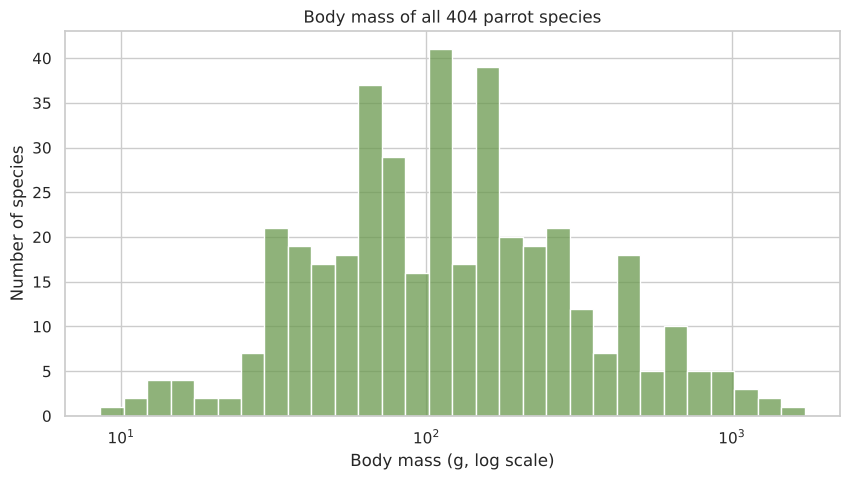

In [49]:
#histogram of body mass
#i used log scale because some parrots are 10 g and some are more than 1,000 g
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(parrots["mass_g"], log_scale=True, bins=30, color="#6A994E", ax=ax)
ax.set(title="Body mass of all 404 parrot species",
       xlabel="Body mass (g, log scale)", ylabel="Number of species")
plt.savefig("../reports/figures/01_mass_hist.png", dpi=200, bbox_inches="tight")
plt.show()
#what I found: most parrots are small or medium, only a few are very big

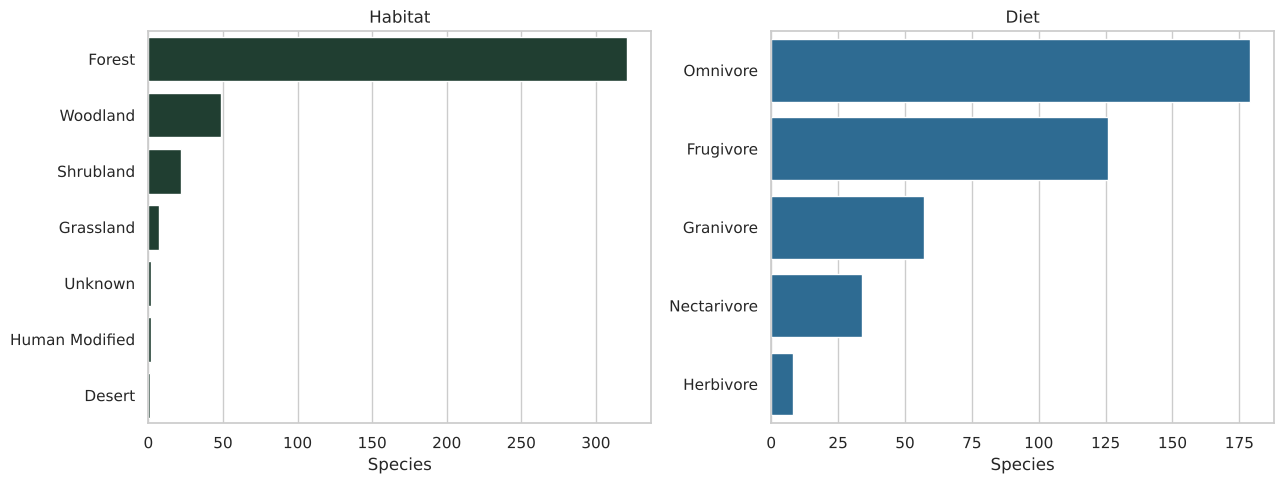

In [50]:
#two plots side by side: habitat and diet
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#order = from the most common to the least common
order = parrots["habitat"].value_counts().index
sns.countplot(y=parrots["habitat"], order=order, color="#1B4332", ax=axes[0])
axes[0].set(title="Habitat", xlabel="Species", ylabel="")

order = parrots["diet"].value_counts().index
sns.countplot(y=parrots["diet"], order=order, color="#1D6FA3", ax=axes[1])
axes[1].set(title="Diet", xlabel="Species", ylabel="")

plt.tight_layout()
plt.savefig("../reports/figures/02_habitat_diet.png", dpi=200, bbox_inches="tight")
plt.show()
#what i found: most parrots live in forests and most of them eat fruit or seeds

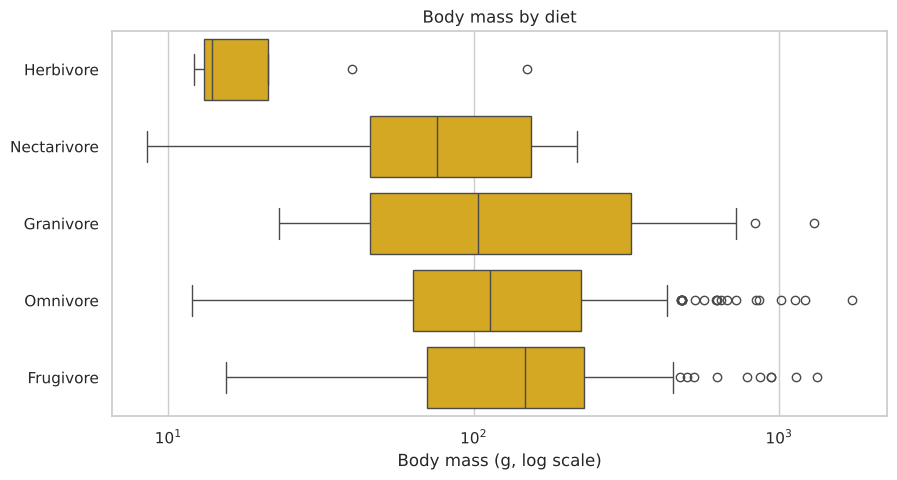

In [51]:
#box plot: is body mass different for each diet?
#i sorted the diets by the median mass so the plot is easier to read
fig, ax = plt.subplots(figsize=(10, 5))
order = parrots.groupby("diet")["mass_g"].median().sort_values().index
sns.boxplot(data=parrots, x="mass_g", y="diet", order=order,
            color="#F2B705", ax=ax)
ax.set_xscale("log")
ax.set(title="Body mass by diet", xlabel="Body mass (g, log scale)", ylabel="")
plt.savefig("../reports/figures/03_mass_box.png", dpi=200, bbox_inches="tight")
plt.show()
#what i found: the herbivores are the smallest (tiny pygmy parrots, Micropsitta)

### 6.2 The trade over time

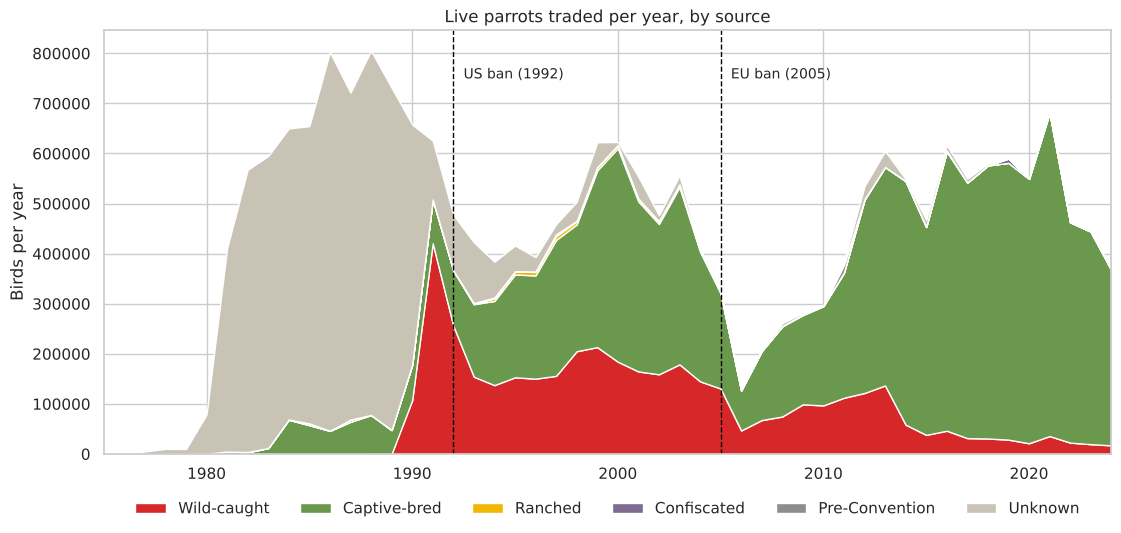

In [52]:
#make a table: years in rows, sources in columns, number of birds in cells
yearly = trade.pivot_table(index="year", columns="source", values="quantity",
                           aggfunc="sum", fill_value=0)
#put the columns in the order i want (wild first)
yearly = yearly[["Wild-caught", "Captive-bred", "Ranched",
                 "Confiscated", "Pre-Convention", "Unknown"]]

colors = ["#D62828", "#6A994E", "#F2B705", "#7D6B91", "#8D8D8D", "#C9C3B5"]

#stacked area: the full height = all birds in that year
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.stackplot(yearly.index, yearly.T.values, labels=yearly.columns, colors=colors)

for year, text in [(1992, "US ban (1992)"), (2005, "EU ban (2005)")]:
    ax.axvline(year, color="black", linestyle="--", linewidth=1)
    ax.text(year + 0.5, 750_000, text, fontsize=10)

ax.set(title="Live parrots traded per year, by source",
       ylabel="Birds per year", xlim=(1975, 2024))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=6, frameon=False)
plt.savefig("../reports/figures/04_trade_over_time.png", dpi=200, bbox_inches="tight")
plt.show()
#what i found: the red part (wild-caught) gets much smaller after each ban

In [53]:
#check the wild share in numbers, by decade
#i used only the known sources so "Unknown" doesn't change the %
known = trade[trade["source"].isin(["Wild-caught", "Captive-bred", "Ranched"])].copy()
known["decade"] = (known["year"] // 10 * 10).astype(str) + "s"

share = known.pivot_table(index="decade", columns="source", values="quantity",
                          aggfunc="sum", observed=True)
(share.div(share.sum(axis=1), axis=0) * 100).round(1)

source,Captive-bred,Ranched,Wild-caught
decade,,,
1970s,100.0,NaN,NaN
1980s,99.8,NaN,0.2
1990s,48.4,1.0,50.6
2000s,65.7,0.7,33.6
2010s,86.0,0.1,13.9
2020s,95.3,0.0,4.7


### 6.3 Who sells, who buys?

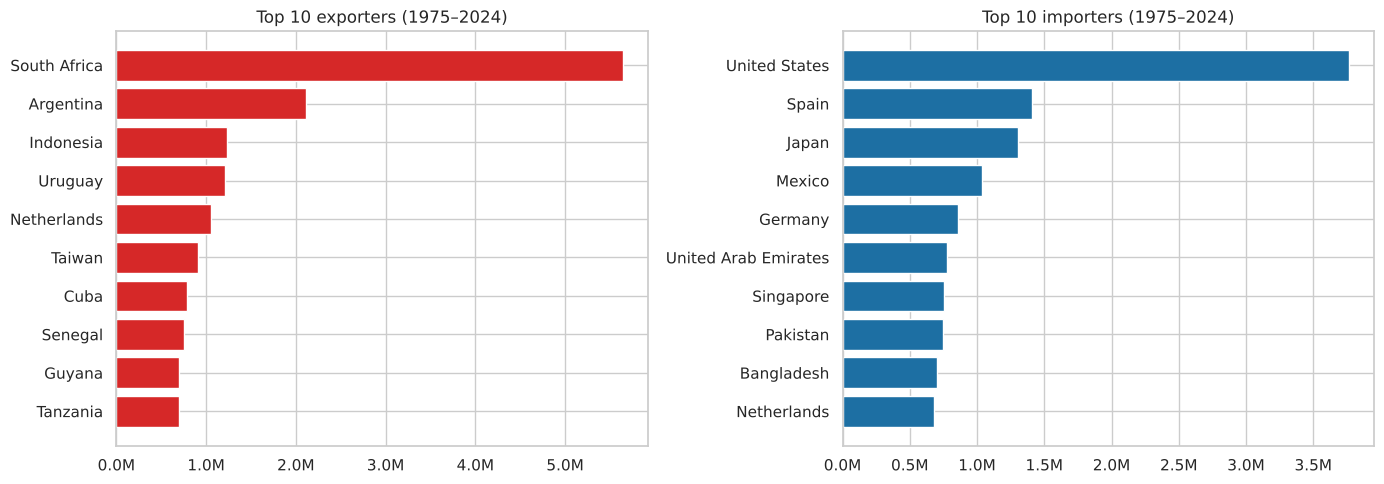

In [54]:
#top 10 exporters and top 10 importers, side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, color in [(axes[0], "exporter", "#D62828"), (axes[1], "importer", "#1D6FA3")]:
    top = trade.groupby(col)["quantity"].sum().nlargest(10).sort_values()
    ax.barh(top.index, top.values, color=color)
    ax.set_title(f"Top 10 {col}s (1975–2024)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))

plt.tight_layout()
plt.savefig("../reports/figures/05_top_countries.png", dpi=200, bbox_inches="tight")
plt.show()

In [55]:
#who buys the most in recent years? (since 2015)
#i wanted to see if the buyers changed from the old years
recent = trade[trade["year"] >= 2015]
recent.groupby("importer")["quantity"].sum().nlargest(10)

importer
Bangladesh              638774
Iraq                    609702
Pakistan                469186
Lebanon                 459105
United Arab Emirates    406808
Indonesia               329952
Kuwait                  307359
Qatar                   255241
Oman                    240611
Saudi Arabia            179387
Name: quantity, dtype: int64

### 6.4 Saudi Arabia & the Gulf 🇸🇦

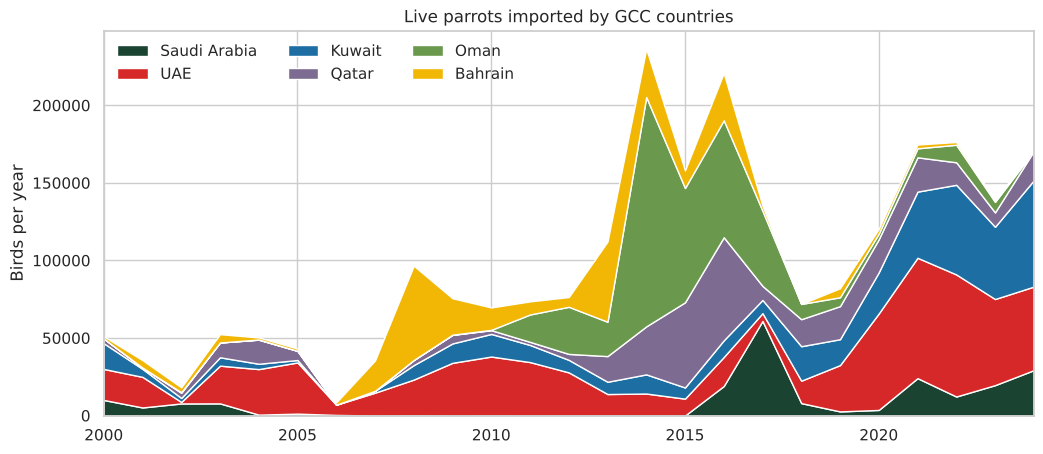

In [56]:
#GCC country codes and their names
gulf = {"SA": "Saudi Arabia", "AE": "UAE", "KW": "Kuwait",
        "QA": "Qatar", "BH": "Bahrain", "OM": "Oman"}

#keep only birds imported by a GCC country
g = trade[trade["importer_code"].isin(gulf)].copy()
g["country"] = g["importer_code"].map(gulf)
g = g.pivot_table(index="year", columns="country", values="quantity",
                  aggfunc="sum", fill_value=0).loc[2000:]
g = g[["Saudi Arabia", "UAE", "Kuwait", "Qatar", "Oman", "Bahrain"]]

fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(g.index, g.T.values, labels=g.columns,
             colors=["#1B4332", "#D62828", "#1D6FA3", "#7D6B91", "#6A994E", "#F2B705"])
ax.set(title="Live parrots imported by GCC countries",
       ylabel="Birds per year", xlim=(2000, 2024))
ax.legend(loc="upper left", ncol=3, frameon=False)
plt.savefig("../reports/figures/06_gulf.png", dpi=200, bbox_inches="tight")
plt.show()

In [57]:
#Saudi Arabia only: total, how much came after 2016, and the top 5 species
sa = trade[trade["importer_code"] == "SA"]
total = sa["quantity"].sum()
after_2016 = sa.loc[sa["year"] >= 2016, "quantity"].sum()

print(f"إجمالي ما استوردته السعودية: {total:,}")
print(f"نسبة اللي وصل بعد 2016: {after_2016 / total:.0%}")
print("\nأكثر 5 أنواع:")
print(sa.groupby("species")["quantity"].sum().nlargest(5))
#what i found: imports almost stopped 2005–2014, then went up a lot (lovebirds first)

إجمالي ما استوردته السعودية: 277,679
نسبة اللي وصل بعد 2016: 65%

أكثر 5 أنواع:
species
Agapornis roseicollis    41871
Agapornis fischeri       39246
Psittacus erithacus      21594
Pyrrhura molinae         15077
Agapornis personatus     11697
Name: quantity, dtype: int64


### 6.5 Is the trade concentrated in a few species?

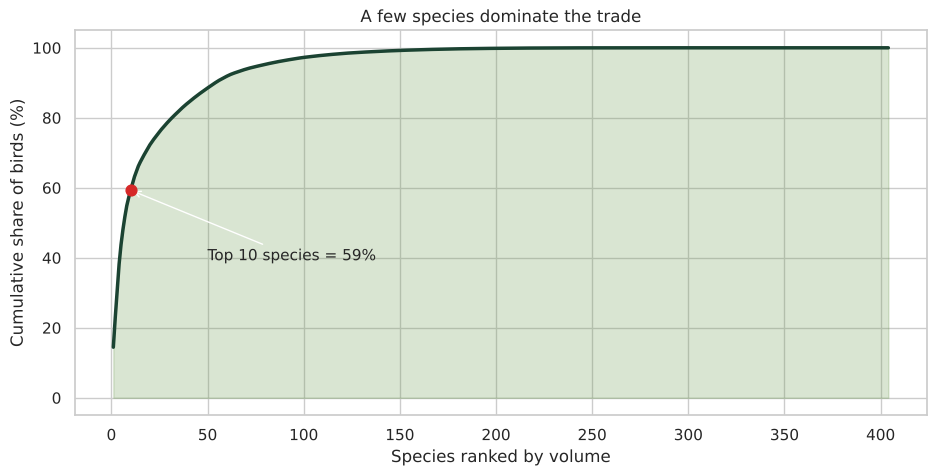

,species,mass_g,diet,total_traded
22,Agapornis fischeri,48.30,Granivore,3187349
318,Psittacus erithacus,333.00,Omnivore,1870797
25,Agapornis personatus,52.38,Granivore,1723325
216,Myiopsitta monachus,120.00,Omnivore,1640183
27,Agapornis roseicollis,53.83,Granivore,1225785
267,Poicephalus senegalus,147.00,Omnivore,952687
31,Alexandrinus krameri,116.11,Omnivore,809910
36,Amazona aestiva,451.00,Frugivore,695646
290,Psephotus haematonotus,61.39,Granivore,512111
39,Amazona amazonica,370.00,Frugivore,459663


In [58]:
#sort species from the most traded to the least
ranked = parrots.sort_values("total_traded", ascending=False)
cum_share = ranked["total_traded"].cumsum() / ranked["total_traded"].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(1, len(cum_share) + 1), cum_share * 100, color="#1B4332", linewidth=2.5)
ax.fill_between(range(1, len(cum_share) + 1), cum_share * 100, color="#6A994E", alpha=0.25)

top10 = cum_share.iloc[9] * 100
ax.scatter([10], [top10], color="#D62828", s=60, zorder=5)
ax.annotate(f"Top 10 species = {top10:.0f}%", (10, top10), (50, top10 - 20),
            arrowprops=dict(arrowstyle="->"), fontsize=11)
ax.set(title="A few species dominate the trade", xlabel="Species ranked by volume",
       ylabel="Cumulative share of birds (%)")
plt.savefig("../reports/figures/07_concentration.png", dpi=200, bbox_inches="tight")
plt.show()

#who are the top 10?
ranked[["species", "mass_g", "diet", "total_traded"]].head(10)

### 6.6 Bivariate & multivariate: does biology predict trade?

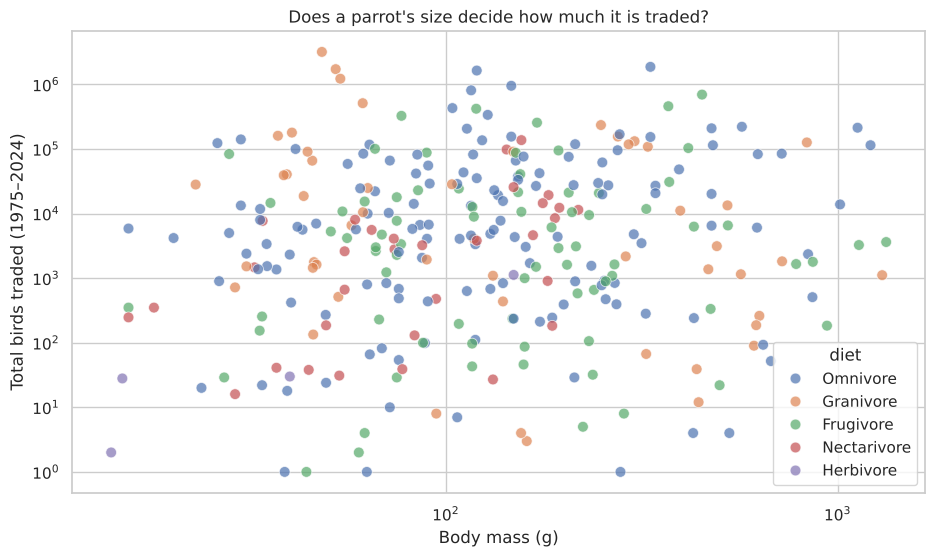

In [59]:
#only species that were traded (log scale cant show 0)
traded = parrots[parrots["in_trade"]]

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=traded, x="mass_g", y="total_traded", hue="diet",
                alpha=0.7, s=60, ax=ax)
ax.set(xscale="log", yscale="log", xlabel="Body mass (g)",
       ylabel="Total birds traded (1975–2024)",
       title="Does a parrot's size decide how much it is traded?")
plt.savefig("../reports/figures/08_mass_vs_trade.png", dpi=200, bbox_inches="tight")
plt.show()
#what i found: the points are everywhere, no clear pattern

In [60]:
#check it with numbers: Spearman correlation
#i used Spearman (not Pearson) because the data is very skewed and has outliers
#+1 because log(0) doesnt work for species with 0 trade
num = pd.DataFrame({
    "log_traded": np.log10(parrots["total_traded"] + 1),
    "log_mass": np.log10(parrots["mass_g"]),
    "log_range": np.log10(parrots["range_km2"]),
})
num.corr(method="spearman").round(2)

,log_traded,log_mass,log_range
log_traded,1.00,0.14,0.47
log_mass,0.14,1.00,0.05
log_range,0.47,0.05,1.00


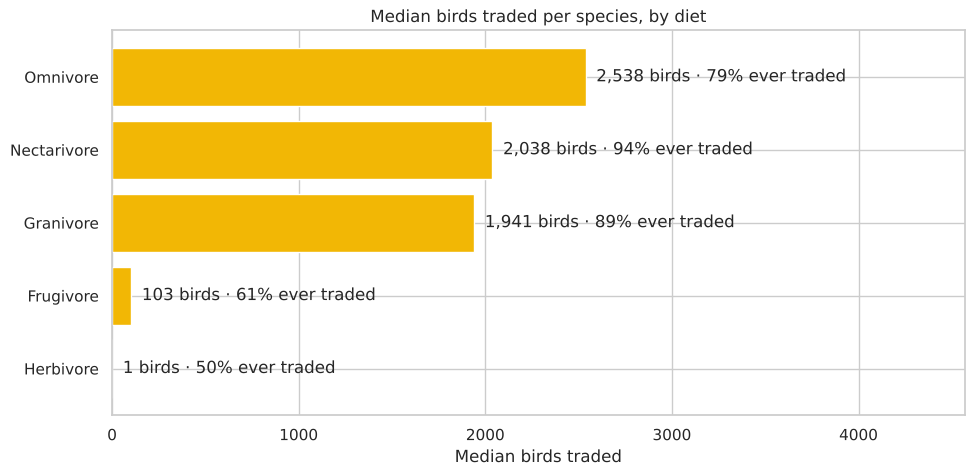

In [61]:
#for each diet: the median birds traded, and how many % of species were ever traded
#i used median not mean because a few species have millions of birds
diet_stats = parrots.groupby("diet").agg(
    median_traded=("total_traded", "median"),
    share_traded=("in_trade", "mean"),
).sort_values("median_traded")

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(diet_stats.index, diet_stats["median_traded"], color="#F2B705")
for i, (m, s) in enumerate(zip(diet_stats["median_traded"], diet_stats["share_traded"])):
    ax.text(m, i, f"  {m:,.0f} birds · {s:.0%} ever traded", va="center")
ax.set_xlim(0, diet_stats["median_traded"].max() * 1.8)
ax.set(title="Median birds traded per species, by diet", xlabel="Median birds traded")
plt.savefig("../reports/figures/09_diet_bar.png", dpi=200, bbox_inches="tight")
plt.show()

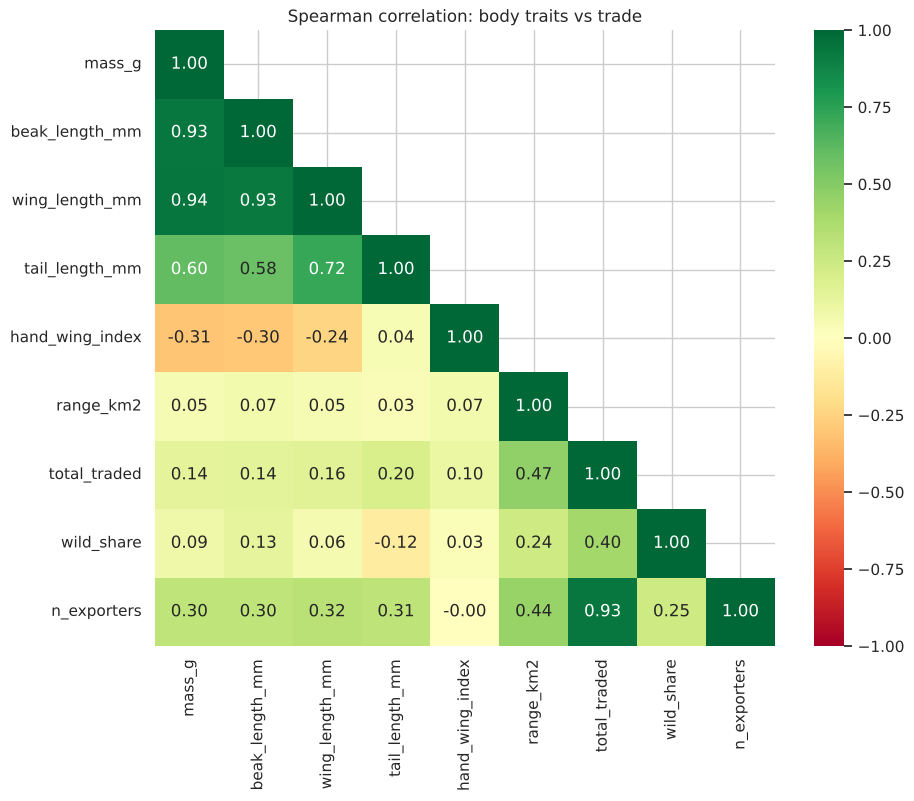

In [62]:
#heatmap: correlation between all body traits and trade numbers
cols = ["mass_g", "beak_length_mm", "wing_length_mm", "tail_length_mm",
        "hand_wing_index", "range_km2", "total_traded", "wild_share", "n_exporters"]
corr = parrots[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
#mask hides the top half because it is the same as the bottom half
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
ax.set_title("Spearman correlation: body traits vs trade")
plt.savefig("../reports/figures/10_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()
#what i found: body size traits are linked to each other, but not much to trade

### 6.7 Outliers: the danger zone ⚠️

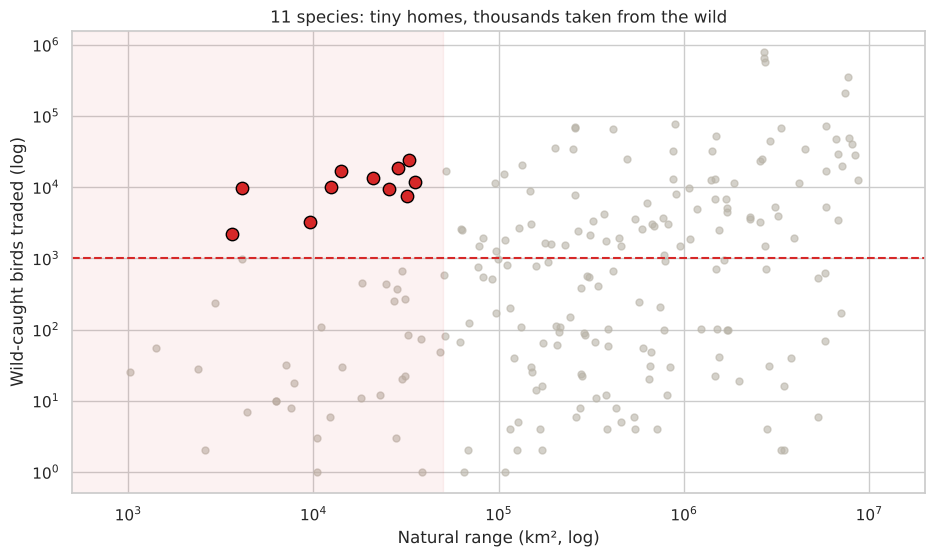

,species,family,range_km2,wild_traded
1,Cacatua ducorpsii,Cockatoos,32952.62,23882
148,Eos bornea,True parrots,28750.89,18352
203,Lorius chlorocercus,True parrots,14033.51,16773
0,Cacatua alba,Cockatoos,20920.49,13323
104,Chalcopsitta cardinalis,True parrots,35346.62,11681
99,Brotogeris pyrrhoptera,True parrots,12451.45,10129
3,Cacatua goffiniana,Cockatoos,4111.87,9709
205,Lorius garrulus,True parrots,25448.01,9504
153,Eos squamata,True parrots,32014.97,7481
114,Charmosyna papou,True parrots,9550.65,3250


In [63]:
#danger zone = small home (range < 50,000 km2) + more than 1,000 birds taken from the wild
#these species cant handle losing many birds because they live in a small area
danger = parrots[(parrots["range_km2"] < 50_000) & (parrots["wild_traded"] > 1_000)] \
    .sort_values("wild_traded", ascending=False)

w = parrots[parrots["wild_traded"] > 0]
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(w["range_km2"], w["wild_traded"], color="#B8B3A7", alpha=0.6, s=25)
ax.scatter(danger["range_km2"], danger["wild_traded"], color="#D62828",
           edgecolor="black", s=80, zorder=5)
ax.axvspan(1, 50_000, color="#D62828", alpha=0.06)
ax.axhline(1_000, color="#D62828", linestyle="--")
ax.set(xscale="log", yscale="log", xlim=(500, 2e7),
       xlabel="Natural range (km², log)", ylabel="Wild-caught birds traded (log)",
       title=f"{len(danger)} species: tiny homes, thousands taken from the wild")
plt.savefig("../reports/figures/11_danger_zone.png", dpi=200, bbox_inches="tight")
plt.show()

danger[["species", "family", "range_km2", "wild_traded"]]
#what i found: 11 species, mostly lories and cockatoos from small islands in Indonesia

## 7 · Insights Summary

### 📈 Patterns
- **22.5 million** live parrots were legally traded between countries from 1975 to 2024.
- Among birds with a known source, the **wild-caught share fell from 50.6% in the 1990s to 4.7% in the 2020s**. The two biggest drops came right after the **US Wild Bird Conservation Act (1992)** and the **EU ban on wild-bird imports (2005)**. Import bans clearly worked.
- The trade is highly concentrated: **10 of 404 species make up 59% of all birds**, led by Fischer's lovebird (3.2M birds).
- **South Africa** is the world's largest exporter (5.6M birds), mostly captive-bred, and the **USA** is the largest importer over the whole period. Since 2015, however, demand has shifted to **South Asia and the Middle East** (Bangladesh, Iraq, Pakistan, Lebanon, UAE).
- **Saudi Arabia** imported **277,679** parrots in total. Imports almost stopped between 2005 and 2014, then surged: **65% arrived after 2016**, led by lovebirds.

### 🔗 Relationships
- **Body size barely predicts trade** (Spearman ρ = 0.14). Big parrots are not traded more than small ones.
- **Range size is the strongest link** (ρ = 0.47). Widespread species are easier to source and cheaper, so they become pet-shop staples.
- **Diet matters:** seed-eaters, nectar-eaters and omnivores are traded about **20× more** than fruit-eaters, and only **61% of fruit-eating species** have ever been traded. Note that AVONET records a species' diet **in the wild**, not in captivity. One possible explanation is that fruit-eaters are harder to keep, but this needs more evidence.
- Body measurements are highly correlated with each other (mass, beak and wing, ρ ≈ 0.9), but none of them drives trade.

### ⚠️ Outliers
- **The danger zone:** **11 species** have a natural range smaller than 50,000 km² (about the size of the Qassim region) yet more than 1,000 wild-caught birds traded. Almost all are lories and cockatoos from Indonesian and Melanesian islands, such as *Cacatua ducorpsii*, *Eos bornea* and *Cacatua goffiniana*.
- **The largest single record:** **124,000 wild-caught monk parakeets** exported from Uruguay to Mexico in 2012. It is a real commercial shipment, so it was kept.
- **The green-cheeked conure** (*Pyrrhura molinae*) breaks the diet pattern: it is classified as a fruit-eater in the wild, yet it ranks **#14 of 404**, with over 326,000 birds traded and **less than 1% wild-caught**. Pet-care guides recommend a **seed-based diet with fresh vegetables** for this species in captivity ([source](https://happybirds.hu/en/parrot-feeding-and-care#pyrrhura)), so its ability to adapt to captive food may explain why it is so popular.

### 💡 Key Takeaway
The parrot trade is not driven by the biggest or most beautiful birds. It runs on **common, widespread, easy-to-breed species**. The trade has largely moved from the wild to captive breeding, but the wild-caught trade that remains hits **small island species** hardest.

## 8 · Limitations & Next Steps

### Limitations
- **Legal, reported trade only:** CITES does not include illegal trafficking, and 2024 data is incomplete because of reporting delays.
- **Exporter and importer figures often disagree.** We used the exporter's figure when available, so totals are best estimates.
- **Four of the most common pet parrots were removed from the CITES lists:** budgerigar, cockatiel, rosy-faced lovebird and rose-ringed parakeet. Their trade after removal is not recorded.
- **Before 1990**, the source of most birds (wild or captive) was not reported.
- **AVONET diet categories describe feeding in the wild**, which can differ from what species eat in captivity.
- **13 rare CITES names** could not be matched to AVONET (less than 0.01% of birds).

### Next Steps
- Add IUCN Red List status to measure the conservation impact.
- Add market prices to test whether rarity raises value.
- Build a classification model to predict which species are at risk of heavy trade.
- Study the Gulf pet-bird market in more depth.